Projet TP Big Data

In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [4]:
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid" , palette="pastel")
plt.rcParams['figure.figsize']=(10, 4.5)

In [11]:
df_raw = pd.read_csv("enquete_agricole_burkina_brut.csv")
df = df_raw.copy()
print("Shape of the dataset:", df.shape)


Shape of the dataset: (2930, 21)


In [12]:
df.head(8)

,id_parcelle,date_enquete,enqueteur,region,culture,superficie_ha,semence,engrais,quantite_engrais_kg,pluviometrie_mm,rendement_kg_ha,stockage,pertes_pct,mode_vente,prix_fcfa_kg,sexe_exploitant,age_exploitant,nb_personnes_menage,membre_cooperative,acces_credit,telephone
0,P01956,09/12/2025,E01,Boucle du Mouhoun,Coton,3.6,Améliorée,Urée,365.00,871.00,"1,991.00",NaN,NaN,Coopérative,275.00,M,80.00,7.00,Non,Non,Oui
1,P02653,03/12/2025,E11,Est,MIL,0.5,Locale,Urée,33.00,723.00,781.00,Sacs PICS,2.80,Commerçant,190.00,Homme,61.00,10.00,Non,NON,Oui
2,P02282,2025-10-16,E02,Boucle du Mouhoun,Sorgho,0.64,Améliorée,Aucun,0.00,773.00,"1,408.00",Magasin coopératif,NaN,Autoconsommation,NaN,M,44.00,7.00,Oui,Non,Oui
3,P01496,2025-11-06,E10,Nord,MIL,2.11,Améliorée,Aucun,0.00,833.00,897.00,Sacs PICS,NaN,Commerçant,160.00,M,52.00,8.00,Oui,Non,Oui
4,P02179,19/12/2025,E06,Centre-Ouest,Sorgho,0.43,Locale,Aucun,0.00,800.00,841.00,Magasin coopératif,NaN,Autoconsommation,NaN,M,33.00,9.00,Non,Oui,Oui
5,P01999,2025-12-01,E06,Centre-Ouest,Sorgho,0.42,Locale,Aucun,0.00,"1,062.00",NaN,Sacs PICS,NaN,Coopérative,145.00,M,45.00,9.00,Non,Non,Oui
6,P00031,2025-10-29,E05,Centre-Ouest,Coton,1.17,Améliorée,NPK,74.00,NaN,"2,585.00",Grenier traditionnel,10.60,Coopérative,285.00,M,45.00,9.00,Oui,Oui,Oui
7,P02030,2025-12-12,E02,Boucle du Mouhoun,Maïs,2.98,Améliorée,Aucun,0.00,767.00,"1,672.00",Grenier traditionnel,11.00,Autoconsommation,NaN,M,45.00,11.00,Oui,Oui,Oui


In [16]:
print(df[['region', 'culture', "semence" , "engrais", "stockage", 'mode_vente', 'sexe_exploitant', 'membre_cooperative']].nunique())
df["region"].value_counts(dropna=False)

region                26
culture               19
semence                6
engrais               11
stockage               3
mode_vente             4
sexe_exploitant        7
membre_cooperative     6
dtype: int64


region
Hauts-Bassins        528
Boucle du Mouhoun    520
Centre-Ouest         395
Nord                 342
Centre               307
Est                  262
Sahel                152
HAUTS-BASSINS         37
CENTRE-OUEST          36
nord                  32
hauts-bassins         31
NORD                  30
centre ouest          29
centre                27
BMH                   25
boucle du mouhoun     25
Boucle Mouhoun        24
EST                   24
Hauts Bassins         22
CENTRE                19
sahel                 17
SAHEL                 16
est                   14
BOUCLE DU MOUHOUN      9
NORD                   4
CENTRE                 3
Name: count, dtype: int64

In [17]:
missing = pd.DataFrame({
    "Valeurs manquantes": df.isna().sum(),
    "pourcentage": (df.isna().mean() * 100).round(1)
}).sort_values("pourcentage", ascending=False)

missing = missing[missing["Valeurs manquantes"] > 0]
print(missing)

                     Valeurs manquantes  pourcentage
prix_fcfa_kg                        827        28.20
pertes_pct                          346        11.80
pluviometrie_mm                     233         8.00
stockage                            206         7.00
acces_credit                        177         6.00
age_exploitant                      150         5.10
nb_personnes_menage                 146         5.00
telephone                           116         4.00
semence                             115         3.90
mode_vente                           91         3.10
membre_cooperative                   89         3.00
quantite_engrais_kg                  87         3.00
superficie_ha                        89         3.00
rendement_kg_ha                      89         3.00
culture                              29         1.00


In [ ]:
#Heatmap

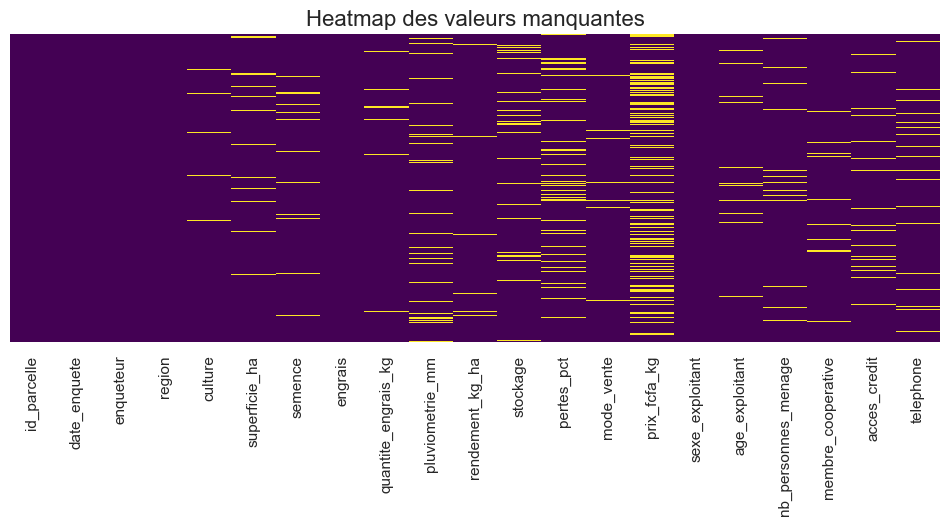

In [19]:
plt.figure(figsize=(12, 4))
sns.heatmap(df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title("Heatmap des valeurs manquantes", fontsize=16)
plt.show()  

In [21]:
n_avant = len(df) 
print("Nombre de lignes avant suppression des doublons:",df.duplicated().sum())
df = df.drop_duplicates()
print("Nombre de lignes après suppression des doublons:",len(df))

Nombre de lignes avant suppression des doublons: 100
Nombre de lignes après suppression des doublons: 2830


In [25]:
map_region = {
    "boucle du mouhoun": "Boucle du Mouhoun", "bmh": "Boucle du Mouhoun", "boucle mouhoun": "Boucle du Mouhoun", "BOUCLE DU MOUHOUN": "Boucle du Mouhoun",
    "hauts-bassins": "Hauts-Bassins", "hauts bassins": "Hauts-Bassins","HAUTS-BASSINS": "Hauts-Bassins", "HAUTS BASSINS": "Hauts-Bassins",
    "centre-ouest": "Centre-Ouest", "centre ouest": "Centre-Ouest", "CENTRE-OUEST": "Centre-Ouest", "CENTRE OUEST": "Centre-Ouest",
    "centre": "Centre", "nord": "Nord", "est": "Est", "sahel": "Sahel","SAHEL": "Sahel", "sud-ouest": "Sud-Ouest", "sud ouest": "Sud-Ouest", "SUD-OUEST": "Sud-Ouest", "SUD OUEST": "Sud-Ouest",
}
df["region"] = df["region"].str.strip().str.lower().map(map_region)
print("Region inconnue:", df["region"].isna().sum())
df["region"].value_counts()

Region inconnue: 0


region
Hauts-Bassins        594
Boucle du Mouhoun    582
Centre-Ouest         445
Nord                 395
Centre               346
Est                  292
Sahel                176
Name: count, dtype: int64

In [24]:
print(df["region"].unique())

<StringArray>
['Boucle du Mouhoun',               'Est',              'Nord',
      'Centre-Ouest',     'Hauts-Bassins',             'Sahel',
            'Centre']
Length: 7, dtype: str
